In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv('Admission_Predict_Ver1.1.csv')

In [3]:
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [4]:
df=df.drop(['Serial No.'],axis=1)

In [5]:
df.isnull().sum()

GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64

In [6]:
df.duplicated().sum()

0

In [7]:
x=df.iloc[:,:-1].values
y=df.iloc[:,-1].values

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
sc=StandardScaler()

In [9]:
x=sc.fit_transform(x)
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.2,random_state=0)

In [10]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [11]:
mod=Sequential()
mod.add(Dense(18,activation='relu',input_dim=7))
mod.add(Dense(8,activation='relu'))
mod.add(Dense(1,activation='linear'))

In [12]:
mod.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 18)                144       
                                                                 
 dense_1 (Dense)             (None, 8)                 152       
                                                                 
 dense_2 (Dense)             (None, 1)                 9         
                                                                 
Total params: 305
Trainable params: 305
Non-trainable params: 0
_________________________________________________________________


In [13]:
mod.compile(loss='mean_squared_error',optimizer='Adam')

In [14]:
sv=mod.fit(xtrain,ytrain,epochs=250)

Epoch 1/250
13/13 [==============================] - 0s 675us/step - loss: 0.7208
Epoch 2/250
13/13 [==============================] - 0s 700us/step - loss: 0.3635
Epoch 3/250
13/13 [==============================] - 0s 962us/step - loss: 0.2002
Epoch 4/250
13/13 [==============================] - 0s 1ms/step - loss: 0.1243
Epoch 5/250
13/13 [==============================] - 0s 681us/step - loss: 0.0962
Epoch 6/250
13/13 [==============================] - 0s 241us/step - loss: 0.0813
Epoch 7/250
13/13 [==============================] - 0s 707us/step - loss: 0.0698
Epoch 8/250
13/13 [==============================] - 0s 727us/step - loss: 0.0611
Epoch 9/250
13/13 [==============================] - 0s 717us/step - loss: 0.0533
Epoch 10/250
13/13 [==============================] - 0s 627us/step - loss: 0.0466
Epoch 11/250
13/13 [==============================] - 0s 1ms/step - loss: 0.0416
Epoch 12/250
13/13 [==============================] - 0s 1ms/step - loss: 0.0369
Epoch 13/250
13/13 

In [15]:
from sklearn.metrics import r2_score

In [16]:
r2_score(mod.predict(xtest),ytest)

4/4 [==============================] - 0s 0s/step


0.6661622337208314

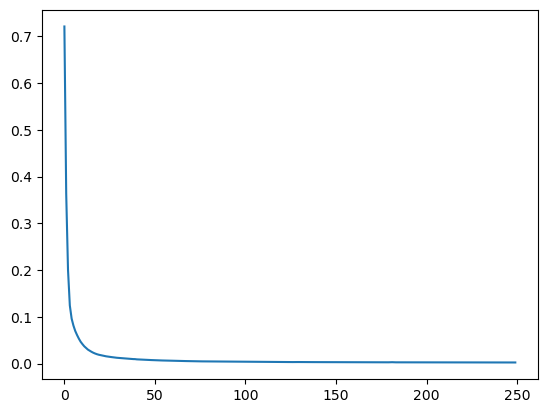

In [17]:
plt.plot(sv.history['loss'])